# Prediksi Kepuasan Penumpang Maskapai Penerbangan Menggunakan Algoritma Logistic Regression

**Tugas Akhir 3 (TA-03) - Pembelajaran Mesin**
Nama: Selsa Shafana Alfiyani | NIM: 301240041 | Teknik Informatika, Universitas Bale Bandung
Dosen Pengampu: Mohammad Bayu Anggara, S.Kom., M.Kom.

## Latar Belakang
Sebuah maskapai penerbangan ingin mengetahui apakah seorang penumpang akan **puas** atau **tidak puas** berdasarkan profil perjalanan dan penilaian layanan. Notebook ini membangun model klasifikasi biner dengan **Regresi Logistik** untuk tujuan tersebut.

- Target: `satisfaction` (1 = satisfied / Puas, 0 = neutral or dissatisfied / Tidak Puas)
- Data latih: `train.csv`, data uji: `test.csv`
- Keluaran notebook: `model/model.pkl`, `model/scaler.pkl`, `model/metrics.json`, dan gambar di `static/img/`

## Daftar Isi
1. Persiapan library
2. Memuat dan memeriksa data
3. Exploratory Data Analysis (EDA)
4. Preprocessing
5. Pemisahan fitur dan scaling
6. Pelatihan model
7. Evaluasi model
8. Interpretasi koefisien
9. Perbandingan dengan class_weight
10. Menyimpan model
11. Uji muat ulang model
12. Catatan interpretasi

**Struktur folder yang dibutuhkan:** notebook ini berada di folder `notebook/`, dan data berada di `../data/train.csv` serta `../data/test.csv`.

## 1. Persiapan Library dan Konfigurasi
Sel ini memuat library, menentukan lokasi folder, dan membuat folder keluaran (`model/` dan `static/img/`) jika belum ada.

In [3]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = "../data"
MODEL_DIR = "../model"
IMG_DIR = "../static/img"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)

BIRU = "#1e3a8a"
BIRU_MUDA = "#60a5fa"
print("Library siap digunakan")

Library siap digunakan


## 2. Memuat dan Memeriksa Data

In [4]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

print("Ukuran data latih :", train.shape)
print("Ukuran data uji   :", test.shape)
train.head()

Ukuran data latih : (103904, 25)
Ukuran data uji   : (25976, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


### 2.1 Informasi kolom, nilai hilang, dan duplikat
Pemeriksaan ini memastikan kualitas data sebelum analisis. Kolom `Arrival Delay in Minutes` diketahui memiliki sedikit nilai hilang.

In [5]:
print("--- Informasi Kolom ---")
train.info()

print("\n--- Nilai Hilang (Data Latih) ---")
hilang = train.isnull().sum()
print(hilang[hilang > 0])

print("\n--- Nilai Hilang (Data Uji) ---")
hilang_uji = test.isnull().sum()
print(hilang_uji[hilang_uji > 0])

print("\nData duplikat (latih):", train.duplicated().sum())
print("Data duplikat (uji)  :", test.duplicated().sum())

--- Informasi Kolom ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location  

### 2.2 Statistik deskriptif
Perhatikan rentang tiap kolom. Skor layanan berskala 0 sampai 5, di mana 0 berarti layanan tidak berlaku bagi penumpang.

In [6]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,103904.0,51951.500000,29994.645522,0.0,25975.75,51951.5,77927.25,103903.0
id,103904.0,64924.210502,37463.812252,1.0,32533.75,64856.5,97368.25,129880.0
Age,103904.0,39.379706,15.114964,7.0,27.00,40.0,51.00,85.0
Flight Distance,103904.0,1189.448375,997.147281,31.0,414.00,843.0,1743.00,4983.0
Inflight wifi service,103904.0,2.729683,1.327829,0.0,2.00,3.0,4.00,5.0
Departure/Arrival time convenient,103904.0,3.060296,1.525075,0.0,2.00,3.0,4.00,5.0
Ease of Online booking,103904.0,2.756901,1.398929,0.0,2.00,3.0,4.00,5.0
Gate location,103904.0,2.976883,1.277621,0.0,2.00,3.0,4.00,5.0
Food and drink,103904.0,3.202129,1.329533,0.0,2.00,3.0,4.00,5.0
Online boarding,103904.0,3.250375,1.349509,0.0,2.00,3.0,4.00,5.0


## 3. Exploratory Data Analysis (EDA)
### 3.1 Distribusi target dan pemeriksaan ketidakseimbangan kelas
Langkah ini menjawab ketentuan tugas untuk memeriksa class imbalance. Jika kedua kelas relatif seimbang, teknik SMOTE tidak diperlukan.

                         jumlah  persen
satisfaction                           
neutral or dissatisfied   58879   56.67
satisfied                 45025   43.33


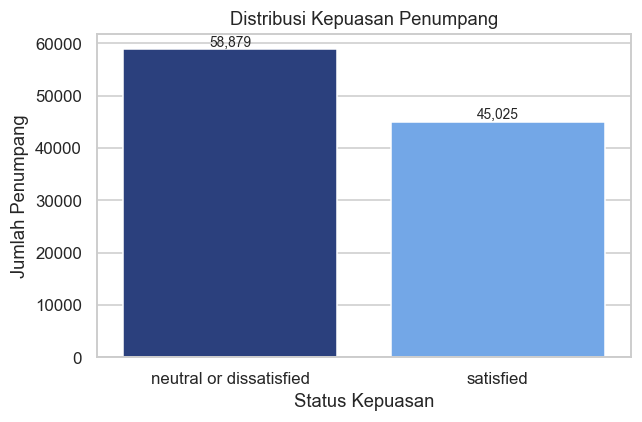

In [7]:
jumlah = train["satisfaction"].value_counts()
persen = train["satisfaction"].value_counts(normalize=True) * 100
print(pd.DataFrame({"jumlah": jumlah, "persen": persen.round(2)}))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="satisfaction", data=train, order=jumlah.index,
              palette=[BIRU, BIRU_MUDA], ax=ax)
ax.set_title("Distribusi Kepuasan Penumpang")
ax.set_xlabel("Status Kepuasan")
ax.set_ylabel("Jumlah Penumpang")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eda_target.png", bbox_inches="tight")
plt.show()

### 3.2 Hubungan fitur kategorikal dengan kepuasan
Kelas penerbangan, tipe perjalanan, dan tipe pelanggan dibandingkan terhadap status kepuasan.

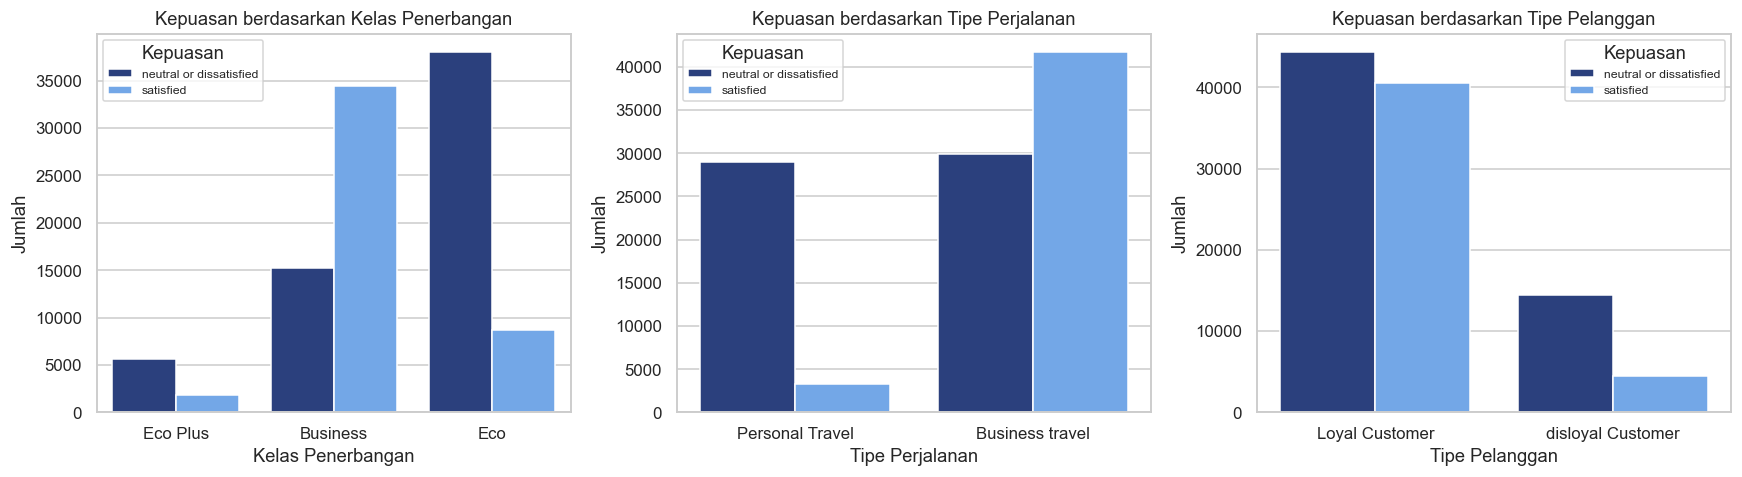

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, kolom, judul in zip(
    axes,
    ["Class", "Type of Travel", "Customer Type"],
    ["Kelas Penerbangan", "Tipe Perjalanan", "Tipe Pelanggan"],
):
    sns.countplot(x=kolom, hue="satisfaction", data=train,
                  palette=[BIRU, BIRU_MUDA], ax=ax)
    ax.set_title(f"Kepuasan berdasarkan {judul}")
    ax.set_xlabel(judul)
    ax.set_ylabel("Jumlah")
    ax.legend(title="Kepuasan", fontsize=8)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eda_kategori.png", bbox_inches="tight")
plt.show()

### 3.3 Hubungan usia dan jarak penerbangan dengan kepuasan

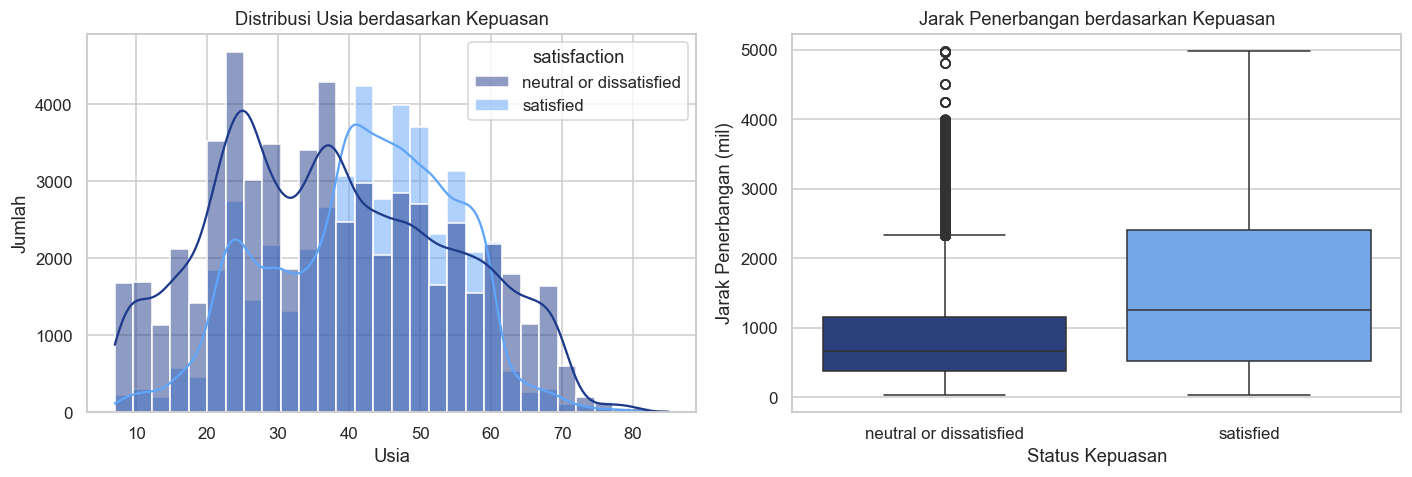

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=train, x="Age", hue="satisfaction", bins=30, kde=True,
             palette=[BIRU, BIRU_MUDA], ax=axes[0])
axes[0].set_title("Distribusi Usia berdasarkan Kepuasan")
axes[0].set_xlabel("Usia")
axes[0].set_ylabel("Jumlah")

sns.boxplot(x="satisfaction", y="Flight Distance", data=train,
            palette=[BIRU, BIRU_MUDA], ax=axes[1])
axes[1].set_title("Jarak Penerbangan berdasarkan Kepuasan")
axes[1].set_xlabel("Status Kepuasan")
axes[1].set_ylabel("Jarak Penerbangan (mil)")

plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eda_numerik.png", bbox_inches="tight")
plt.show()

### 3.4 Skor layanan: penumpang puas vs tidak puas
Grafik ini menunjukkan layanan mana yang paling membedakan kedua kelompok penumpang.

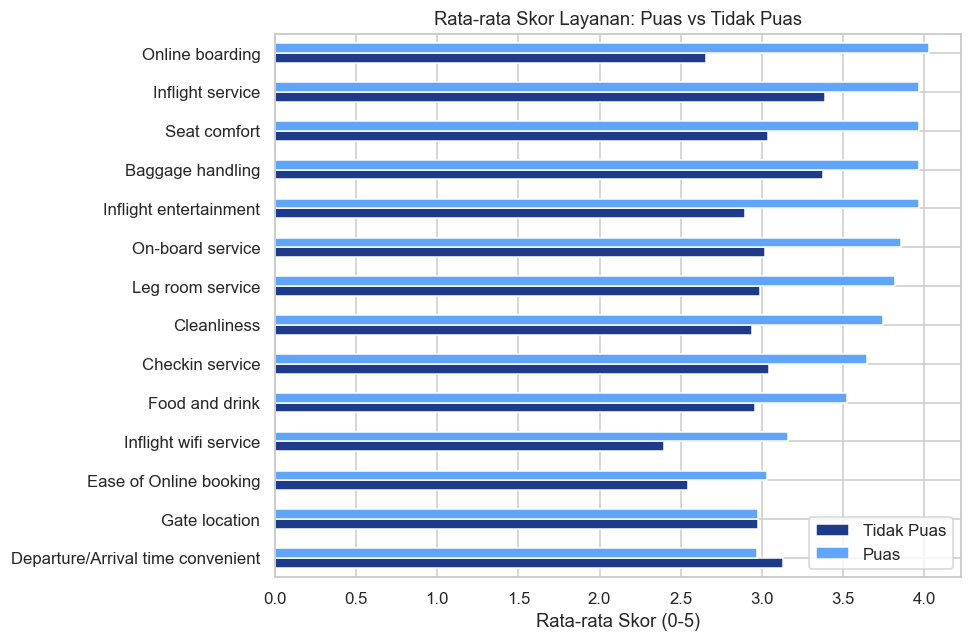

In [10]:
KOLOM_LAYANAN = [
    "Inflight wifi service", "Departure/Arrival time convenient",
    "Ease of Online booking", "Gate location", "Food and drink",
    "Online boarding", "Seat comfort", "Inflight entertainment",
    "On-board service", "Leg room service", "Baggage handling",
    "Checkin service", "Inflight service", "Cleanliness",
]

tmp = train.copy()
tmp["puas"] = (tmp["satisfaction"] == "satisfied").astype(int)
rata = tmp.groupby("puas")[KOLOM_LAYANAN].mean().T
rata.columns = ["Tidak Puas", "Puas"]
rata = rata.sort_values("Puas")

ax = rata.plot(kind="barh", figsize=(9, 6), color=[BIRU, BIRU_MUDA])
ax.set_title("Rata-rata Skor Layanan: Puas vs Tidak Puas")
ax.set_xlabel("Rata-rata Skor (0-5)")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eda_layanan.png", bbox_inches="tight")
plt.show()

## 4. Preprocessing
Langkah-langkah:
1. Membuang kolom `Unnamed: 0` dan `id` (hanya nomor urut dan identitas, tidak bermakna bagi prediksi).
2. Mengisi nilai hilang `Arrival Delay in Minutes` dengan **median data latih** (nilai yang sama dipakai untuk data uji dan aplikasi web agar tidak terjadi kebocoran data).
3. Encoding kategorikal: Gender, Customer Type, dan Type of Travel dipetakan ke 0/1. Class dipetakan berurutan (Eco 0, Eco Plus 1, Business 2).
4. Target dipetakan menjadi 0 (Tidak Puas) dan 1 (Puas).

Fungsi `praproses` dipakai untuk data latih maupun data uji agar perlakuannya identik.

In [11]:
KOLOM_BUANG = ["Unnamed: 0", "id"]

MAP_GENDER = {"Female": 0, "Male": 1}
MAP_PELANGGAN = {"disloyal Customer": 0, "Loyal Customer": 1}
MAP_PERJALANAN = {"Personal Travel": 0, "Business travel": 1}
MAP_KELAS = {"Eco": 0, "Eco Plus": 1, "Business": 2}
MAP_TARGET = {"neutral or dissatisfied": 0, "satisfied": 1}

MEDIAN_ARRIVAL = float(train["Arrival Delay in Minutes"].median())
print("Median Arrival Delay (data latih):", MEDIAN_ARRIVAL)

def praproses(df):
    d = df.drop(columns=KOLOM_BUANG).copy()
    d["Arrival Delay in Minutes"] = d["Arrival Delay in Minutes"].fillna(MEDIAN_ARRIVAL)
    d["Gender"] = d["Gender"].map(MAP_GENDER)
    d["Customer Type"] = d["Customer Type"].map(MAP_PELANGGAN)
    d["Type of Travel"] = d["Type of Travel"].map(MAP_PERJALANAN)
    d["Class"] = d["Class"].map(MAP_KELAS)
    d["satisfaction"] = d["satisfaction"].map(MAP_TARGET)
    return d

train_p = praproses(train)
test_p = praproses(test)

print("Sisa nilai hilang (latih):", train_p.isnull().sum().sum())
print("Sisa nilai hilang (uji)  :", test_p.isnull().sum().sum())
train_p.head()

Median Arrival Delay (data latih): 0.0
Sisa nilai hilang (latih): 0
Sisa nilai hilang (uji)  : 0


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,1,1,13,0,1,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,0
1,1,0,25,1,2,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,0
2,0,1,26,1,2,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,1
3,0,1,25,1,2,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,0
4,1,1,61,1,2,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,1


### 4.1 Korelasi antar fitur
Heatmap dipakai untuk melihat fitur yang paling terkait dengan target dan memeriksa multikolinearitas. Perhatikan korelasi yang sangat tinggi antara keterlambatan keberangkatan dan kedatangan.

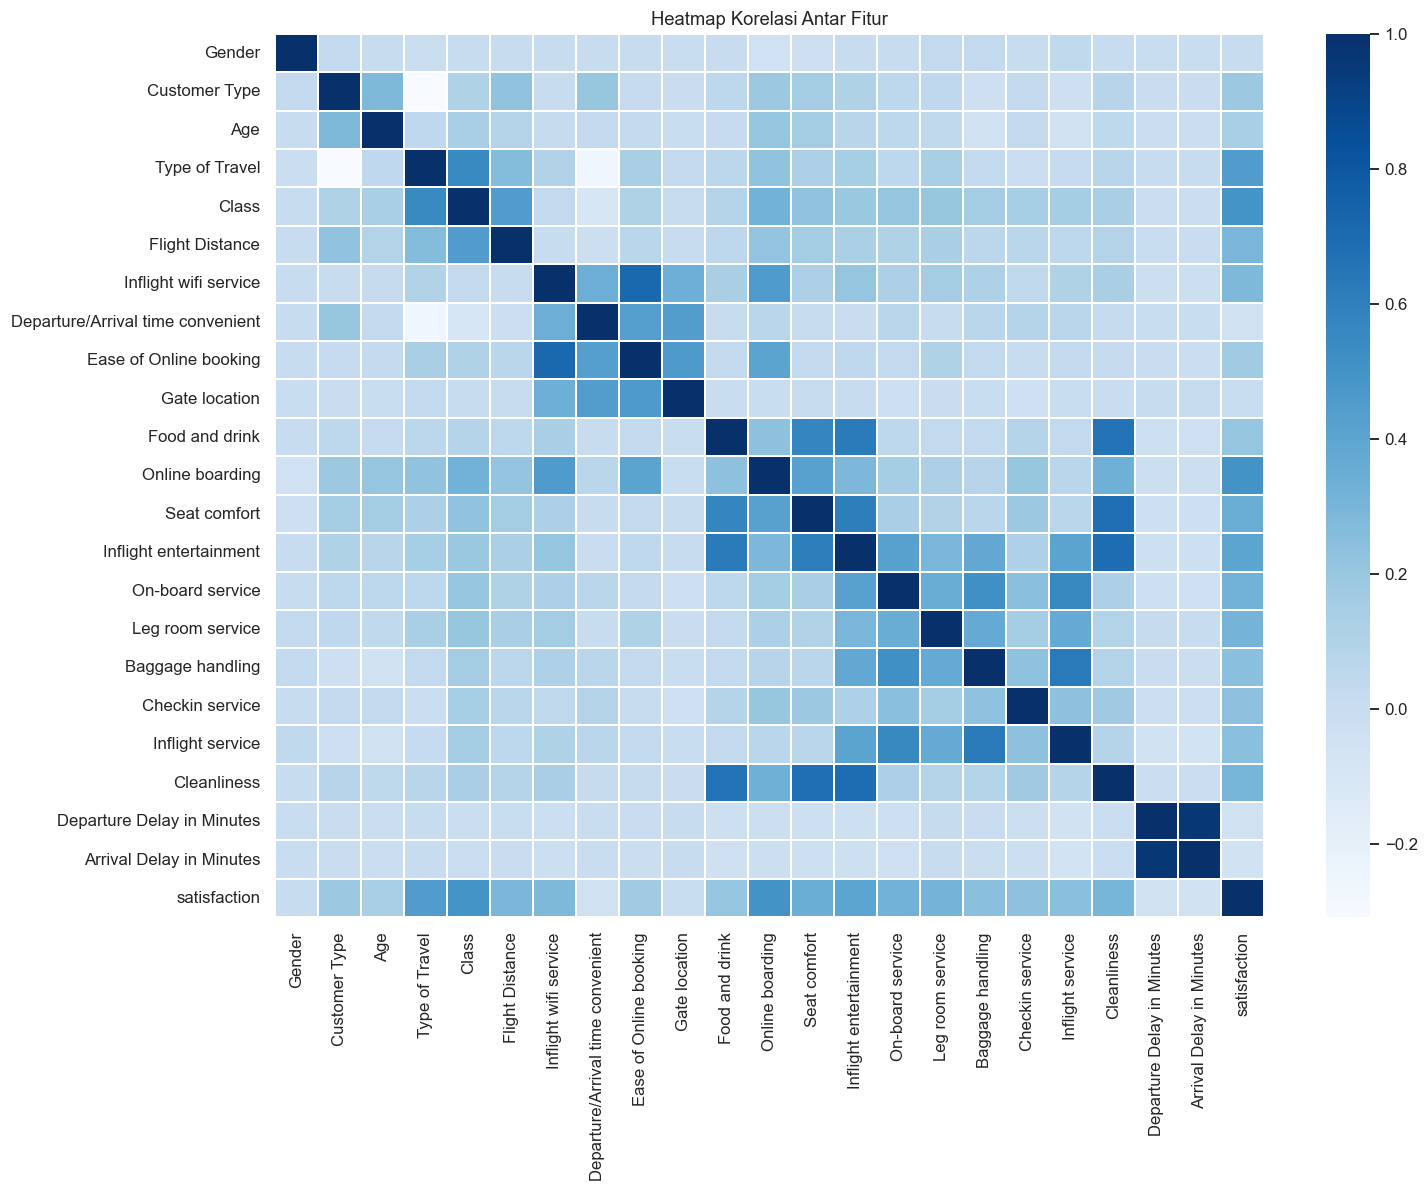

Korelasi fitur dengan target (urut):
Online boarding                      0.504
Class                                0.494
Type of Travel                       0.449
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.313
Cleanliness                          0.305
Flight Distance                      0.299
Inflight wifi service                0.284
Baggage handling                     0.248
Inflight service                     0.245
Checkin service                      0.236
Food and drink                       0.210
Customer Type                        0.188
Ease of Online booking               0.172
Age                                  0.137
Gender                               0.012
Gate location                        0.001
Departure Delay in Minutes          -0.050
Departure/Arrival time convenient   -0.052
Arrival Delay in Minutes            -0.057
Name: satisfactio

In [12]:
korelasi = train_p.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(korelasi, cmap="Blues", annot=False, linewidths=0.3)
plt.title("Heatmap Korelasi Antar Fitur")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eda_korelasi.png", bbox_inches="tight")
plt.show()

print("Korelasi fitur dengan target (urut):")
print(korelasi["satisfaction"].drop("satisfaction").sort_values(ascending=False).round(3))

print("\nKorelasi Departure Delay vs Arrival Delay:",
      round(train_p["Departure Delay in Minutes"].corr(train_p["Arrival Delay in Minutes"]), 3))

## 5. Pemisahan Fitur dan Scaling
Data latih dan data uji sudah disediakan terpisah, sehingga tidak perlu `train_test_split`. `StandardScaler` hanya dipelajari (`fit`) dari data latih, lalu diterapkan ke data uji (`transform`) agar tidak ada kebocoran informasi. Scaling dilakukan pada fitur numerik; fitur biner dan ordinal dibiarkan apa adanya.

In [13]:
FITUR = [c for c in train_p.columns if c != "satisfaction"]
KOLOM_NUMERIK = ["Age", "Flight Distance", "Departure Delay in Minutes",
                 "Arrival Delay in Minutes"] + KOLOM_LAYANAN

X_train = train_p[FITUR].copy()
y_train = train_p["satisfaction"]
X_test = test_p[FITUR].copy()
y_test = test_p["satisfaction"]

scaler = StandardScaler()
X_train[KOLOM_NUMERIK] = scaler.fit_transform(X_train[KOLOM_NUMERIK])
X_test[KOLOM_NUMERIK] = scaler.transform(X_test[KOLOM_NUMERIK])

print("Jumlah fitur       :", len(FITUR))
print("Fitur numerik (scaling):", len(KOLOM_NUMERIK))
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

Jumlah fitur       : 22
Fitur numerik (scaling): 18
X_train: (103904, 22) | X_test: (25976, 22)


## 6. Pelatihan Model Regresi Logistik
Model memakai solver `lbfgs`. Validasi silang 5-fold pada data latih dipakai untuk memeriksa kestabilan model (jika AUC validasi silang mirip dengan AUC data uji, model tidak overfitting).

In [14]:
model = LogisticRegression(solver="lbfgs", max_iter=1000, random_state=42)
model.fit(X_train, y_train)

print("Model selesai dilatih")
print("Intercept:", round(float(model.intercept_[0]), 4))

cv_auc = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc")
print("AUC validasi silang (5-fold):", cv_auc.round(4))
print("Rata-rata AUC validasi silang:", round(cv_auc.mean(), 4))

Model selesai dilatih
Intercept: -4.4196
AUC validasi silang (5-fold): [0.9267 0.924  0.9233 0.9262 0.9322]
Rata-rata AUC validasi silang: 0.9265


## 7. Evaluasi Model
### 7.1 Metrik klasifikasi pada data uji
Kelas positif adalah **Puas**. Accuracy, Precision, Recall, F1-Score, dan AUC dihitung dari data uji yang tidak dipakai saat pelatihan.

In [15]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print("--- Classification Report ---")
print(classification_report(y_test, y_pred,
      target_names=["Tidak Puas", "Puas"], digits=4))

print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"AUC       : {auc:.4f}")

--- Classification Report ---
              precision    recall  f1-score   support

  Tidak Puas     0.8736    0.9009    0.8871     14573
        Puas     0.8681    0.8335    0.8504     11403

    accuracy                         0.8713     25976
   macro avg     0.8709    0.8672    0.8687     25976
weighted avg     0.8712    0.8713    0.8710     25976

Accuracy  : 0.8713
Precision : 0.8681
Recall    : 0.8335
F1-Score  : 0.8504
AUC       : 0.9255


### 7.2 Confusion Matrix
- **TN**: tidak puas, diprediksi tidak puas
- **FP**: tidak puas, diprediksi puas (maskapai mengira penumpang puas padahal tidak)
- **FN**: puas, diprediksi tidak puas
- **TP**: puas, diprediksi puas

TN = 13129 | FP = 1444 | FN = 1899 | TP = 9504


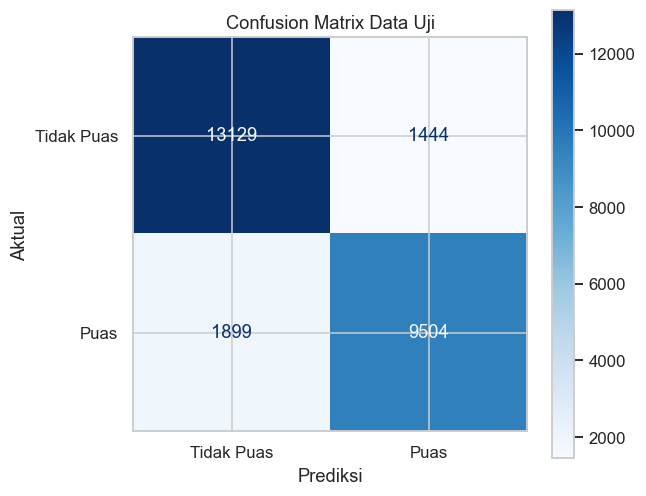

In [16]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=["Tidak Puas", "Puas"]).plot(
    cmap="Blues", ax=ax, values_format="d")
ax.set_title("Confusion Matrix Data Uji")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Aktual")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eval_confusion.png", bbox_inches="tight")
plt.show()

### 7.3 Kurva ROC dan AUC
Kurva yang melengkung ke sudut kiri atas menandakan kemampuan membedakan kelas yang baik. Garis putus-putus adalah tebakan acak.

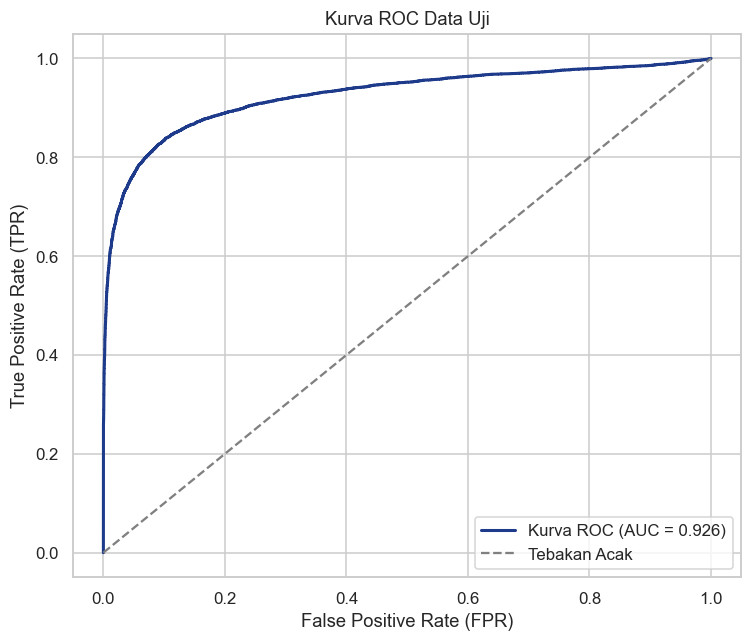

In [17]:
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color=BIRU, lw=2, label=f"Kurva ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Tebakan Acak")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Kurva ROC Data Uji")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eval_roc.png", bbox_inches="tight")
plt.show()

### 7.4 Tabel threshold
Tabel ini menunjukkan perubahan Precision, Recall, dan F1-Score pada berbagai ambang batas. Tabel disimpan ke `metrics.json` dan dipakai pada slider di aplikasi web untuk menjelaskan trade-off Precision vs Recall.

In [18]:
baris = []
for t in np.round(np.arange(0.05, 1.0, 0.05), 2):
    pred_t = (y_proba >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_t, labels=[0, 1]).ravel()
    baris.append({
        "threshold": float(t),
        "accuracy": float(accuracy_score(y_test, pred_t)),
        "precision": float(precision_score(y_test, pred_t, zero_division=0)),
        "recall": float(recall_score(y_test, pred_t)),
        "f1": float(f1_score(y_test, pred_t, zero_division=0)),
        "tn": int(tn_t), "fp": int(fp_t), "fn": int(fn_t), "tp": int(tp_t),
    })
tabel_threshold = pd.DataFrame(baris)
tabel_threshold.round(4)

,threshold,accuracy,precision,recall,f1,tn,fp,fn,tp
0,0.05,0.6201,0.5373,0.9683,0.6911,5065,9508,361,11042
1,0.10,0.7105,0.6092,0.9494,0.7422,7629,6944,577,10826
2,0.15,0.7633,0.6640,0.9328,0.7758,9190,5383,766,10637
3,0.20,0.7964,0.7061,0.9186,0.7985,10213,4360,928,10475
4,0.25,0.8211,0.7431,0.9056,0.8163,11002,3571,1076,10327
5,0.30,0.8375,0.7731,0.8917,0.8281,11588,2985,1235,10168
6,0.35,0.8508,0.8007,0.8789,0.8380,12078,2495,1381,10022
7,0.40,0.8602,0.8246,0.8656,0.8446,12473,2100,1532,9871
8,0.45,0.8672,0.8476,0.8504,0.8490,12830,1743,1706,9697
9,0.50,0.8713,0.8681,0.8335,0.8504,13129,1444,1899,9504


## 8. Interpretasi Koefisien
Karena fitur numerik sudah distandarisasi, besar koefisien dapat dibandingkan antar fitur. Koefisien positif menaikkan peluang Puas, negatif menurunkannya. `odds_ratio` = exp(koefisien).

Catatan: koefisien keterlambatan keberangkatan dan kedatangan saling berlawanan tanda karena keduanya berkorelasi sangat kuat (multikolinearitas), sehingga sebaiknya dibaca sebagai satu kelompok.

                                fitur  koefisien  odds_ratio
0                      Type of Travel     2.7376     15.4503
1                       Customer Type     1.9968      7.3657
2                     Online boarding     0.8340      2.3025
3               Inflight wifi service     0.5113      1.6675
4                     Checkin service     0.4127      1.5110
5                    On-board service     0.3946      1.4838
6                               Class     0.3571      1.4292
7                    Leg room service     0.3351      1.3980
8                         Cleanliness     0.2904      1.3369
9                    Baggage handling     0.1617      1.1755
10         Departure Delay in Minutes     0.1588      1.1721
11                   Inflight service     0.1434      1.1542
12                       Seat comfort     0.0933      1.0978
13             Inflight entertainment     0.0799      1.0832
14                             Gender     0.0448      1.0458
15                      

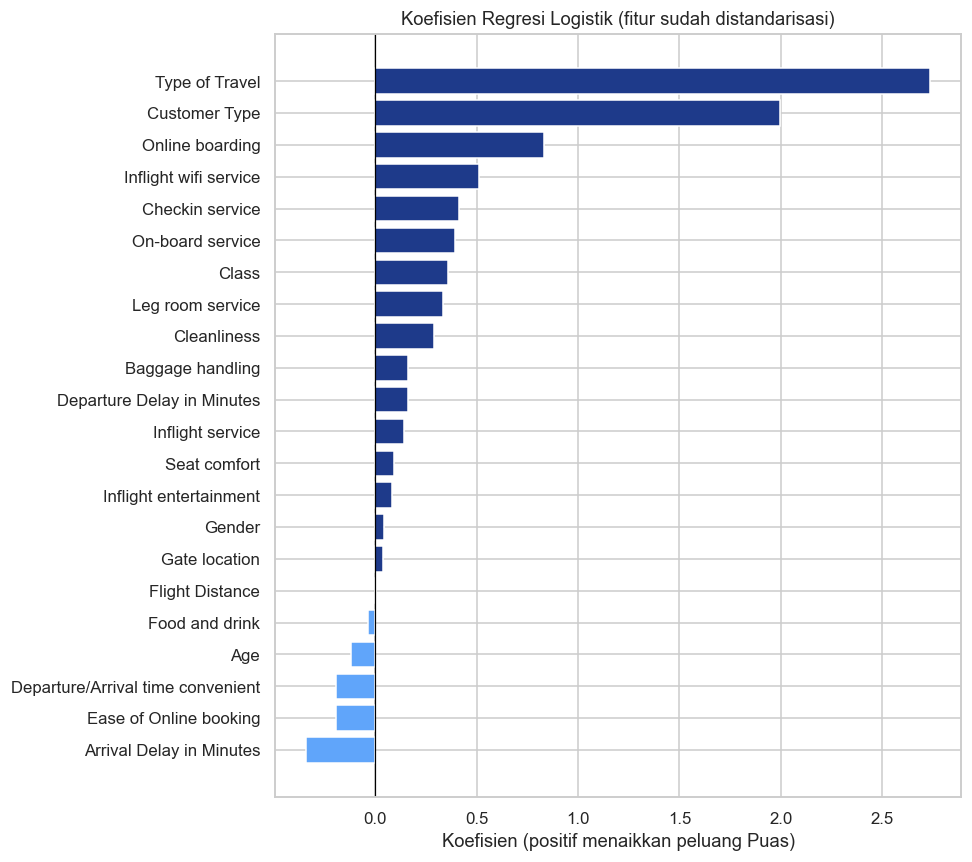

In [19]:
bobot = pd.DataFrame({
    "fitur": FITUR,
    "koefisien": model.coef_[0],
})
bobot["odds_ratio"] = np.exp(bobot["koefisien"])
bobot = bobot.sort_values("koefisien", ascending=False).reset_index(drop=True)
print(bobot.round(4).to_string())

urut = bobot.sort_values("koefisien")
warna = [BIRU_MUDA if k < 0 else BIRU for k in urut["koefisien"]]
plt.figure(figsize=(9, 8))
plt.barh(urut["fitur"], urut["koefisien"], color=warna)
plt.axvline(0, color="black", lw=0.8)
plt.title("Koefisien Regresi Logistik (fitur sudah distandarisasi)")
plt.xlabel("Koefisien (positif menaikkan peluang Puas)")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/eval_koefisien.png", bbox_inches="tight")
plt.show()

## 9. Perbandingan dengan `class_weight='balanced'`
Kelas pada data ini relatif seimbang, sehingga SMOTE tidak diperlukan. Sebagai pembanding, model dengan `class_weight='balanced'` dilatih. Perhatikan bagaimana Precision dan Recall bergeser, sementara AUC hampir sama.

In [20]:
model_seimbang = LogisticRegression(solver="lbfgs", max_iter=1000,
                                    class_weight="balanced", random_state=42)
model_seimbang.fit(X_train, y_train)
pred_s = model_seimbang.predict(X_test)
proba_s = model_seimbang.predict_proba(X_test)[:, 1]

perbandingan = pd.DataFrame({
    "Model": ["Standar", "class_weight=balanced"],
    "Accuracy": [acc, accuracy_score(y_test, pred_s)],
    "Precision": [prec, precision_score(y_test, pred_s)],
    "Recall": [rec, recall_score(y_test, pred_s)],
    "F1-Score": [f1, f1_score(y_test, pred_s)],
    "AUC": [auc, roc_auc_score(y_test, proba_s)],
}).round(4)
print(perbandingan.to_string())

                   Model  Accuracy  Precision  Recall  F1-Score     AUC
0                Standar    0.8713     0.8681  0.8335    0.8504  0.9255
1  class_weight=balanced    0.8656     0.8415  0.8550    0.8482  0.9256


## 10. Menyimpan Model, Scaler, dan Metrik
Model dan scaler disimpan dengan Joblib. `metrics.json` berisi seluruh angka evaluasi, tabel threshold, koefisien, urutan fitur, dan pemetaan encoding yang dibaca oleh aplikasi Flask.

In [21]:
joblib.dump(model, f"{MODEL_DIR}/model.pkl")
joblib.dump(scaler, f"{MODEL_DIR}/scaler.pkl")

titik = np.linspace(0, len(fpr) - 1, 120).astype(int)
metrics = {
    "n_train": int(len(train_p)),
    "n_test": int(len(test_p)),
    "distribusi_latih": {
        "tidak_puas": int((y_train == 0).sum()),
        "puas": int((y_train == 1).sum()),
    },
    "accuracy": float(acc),
    "precision": float(prec),
    "recall": float(rec),
    "f1": float(f1),
    "auc": float(auc),
    "cv_auc_mean": float(cv_auc.mean()),
    "confusion": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "roc": {"fpr": [round(float(fpr[i]), 4) for i in titik],
            "tpr": [round(float(tpr[i]), 4) for i in titik]},
    "threshold": baris,
    "koefisien": [
        {"fitur": r.fitur, "koefisien": float(r.koefisien), "odds_ratio": float(r.odds_ratio)}
        for r in bobot.itertuples()
    ],
    "intercept": float(model.intercept_[0]),
    "fitur_urut": FITUR,
    "kolom_numerik": KOLOM_NUMERIK,
    "median_arrival_delay": MEDIAN_ARRIVAL,
    "peta": {
        "Gender": MAP_GENDER,
        "Customer Type": MAP_PELANGGAN,
        "Type of Travel": MAP_PERJALANAN,
        "Class": MAP_KELAS,
    },
}

with open(f"{MODEL_DIR}/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print("Tersimpan:", sorted(os.listdir(MODEL_DIR)))

Tersimpan: ['metrics.json', 'model.pkl', 'scaler.pkl']


## 11. Uji Muat Ulang Model
Memastikan file yang tersimpan dapat dimuat kembali dan menghasilkan prediksi yang benar.

In [22]:
model_muat = joblib.load(f"{MODEL_DIR}/model.pkl")
scaler_muat = joblib.load(f"{MODEL_DIR}/scaler.pkl")

contoh = X_test.iloc[[0]].copy()
prob = model_muat.predict_proba(contoh)[0, 1]
label = "Puas" if prob >= 0.5 else "Tidak Puas"
aktual = "Puas" if y_test.iloc[0] == 1 else "Tidak Puas"
print(f"Probabilitas Puas: {prob:.4f} | Prediksi: {label} | Aktual: {aktual}")

Probabilitas Puas: 0.9315 | Prediksi: Puas | Aktual: Puas


## 12. Catatan Interpretasi
- **Kinerja model:** AUC yang tinggi pada data uji yang besar menunjukkan model mampu membedakan penumpang puas dan tidak puas dengan baik. AUC validasi silang yang mirip dengan AUC data uji menandakan model tidak overfitting.
- **Kesalahan yang paling merugikan:** False Positive (penumpang tidak puas diprediksi puas) karena maskapai kehilangan kesempatan memperbaiki pengalaman penumpang. Karena itu kemampuan mendeteksi penumpang tidak puas dan Precision kelas Puas perlu diperhatikan.
- **Trade-off:** menaikkan ambang batas membuat model lebih berhati-hati menyebut Puas (Precision naik, Recall turun), dan sebaliknya.
- **Faktor penting:** tipe perjalanan, tipe pelanggan, dan boarding online termasuk faktor dengan pengaruh terbesar. Pengaruh ini adalah hubungan statistik, bukan sebab-akibat.
- **Class imbalance:** distribusi target relatif seimbang sehingga SMOTE tidak diperlukan.
- **Langkah berikutnya:** model dan scaler yang tersimpan dipakai oleh aplikasi web Flask (`app.py`).